# Ridge Regression CC Visualization

**Figure 1:** BoW — Subject 2 | Subject 3 
**Figure 2:** Word2Vec and GloVe — W2V on top, GloVe on bottom; Subject 2 | Subject 3 columns.

In [1]:
# packages
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from pathlib import Path

# styles
plt.rcParams.update({
    'font.family':       'sans-serif',
    'font.size':         12,
    'axes.titlesize':    14,
    'axes.labelsize':    12,
    'axes.spines.top':   False,
    'axes.spines.right': False,
    'axes.linewidth':    0.8,
    'xtick.major.width': 0.8,
    'ytick.major.width': 0.8,
    'legend.frameon':    False,
    'figure.dpi':        150,
})

## 1. Load Data

In [2]:
# path configuration
REPO_RESULTS = Path('../results/ridge_results')          

# load Word2Vec
cc_w2v_s2 = np.load(REPO_RESULTS / 'cc_w2v_subject2.npy')
cc_w2v_s3 = np.load(REPO_RESULTS / 'cc_w2v_subject3.npy')

# load GloVe
cc_glove_s2 = np.load(REPO_RESULTS / 'cc_subject2_glove.npy')
cc_glove_s3 = np.load(REPO_RESULTS / 'cc_subject3_glove.npy')

# load BoW
cc_bow_s2 = np.load(REPO_RESULTS / 'cc_bow_final_subject2.npy')
cc_bow_s3 = np.load(REPO_RESULTS / 'cc_bow_final_subject3.npy')

# print('Shapes loaded:')
# print(f'  BoW    S2: {cc_bow_s2.shape},   S3: {cc_bow_s3.shape}')
# print(f'  W2V    S2: {cc_w2v_s2.shape},   S3: {cc_w2v_s3.shape}')
# print(f'  GloVe  S2: {cc_glove_s2.shape}, S3: {cc_glove_s3.shape}')

In [5]:
# ── Quick sanity-check stats ───────────────────────────────────────────────────
def summarise(name, arr):
    fin = arr[np.isfinite(arr)]
    print(f'{name:20s}  n={len(fin):>7,}  mean={fin.mean():.4f}  '
          f'median={np.median(fin):.4f}  '
          f'top1%={np.percentile(fin, 99):.4f}  '
          f'top5%={np.percentile(fin, 95):.4f}')

for label, arr in [
    ('BoW S2',    cc_bow_s2),
    ('BoW S3',    cc_bow_s3),
    ('W2V S2',    cc_w2v_s2),
    ('W2V S3',    cc_w2v_s3),
    ('GloVe S2',  cc_glove_s2),
    ('GloVe S3',  cc_glove_s3),
]:
    summarise(label, arr)

BoW S2                n= 94,251  mean=0.0001  median=0.0001  top1%=0.0343  top5%=0.0235
BoW S3                n= 95,556  mean=0.0069  median=0.0060  top1%=0.0513  top5%=0.0343
W2V S2                n= 94,251  mean=0.0080  median=0.0062  top1%=0.0597  top5%=0.0384
W2V S3                n= 95,556  mean=0.0136  median=0.0103  top1%=0.0847  top5%=0.0531
GloVe S2              n= 94,251  mean=0.0072  median=0.0055  top1%=0.0608  top5%=0.0374
GloVe S3              n= 95,556  mean=0.0143  median=0.0116  top1%=0.0792  top5%=0.0514


shared axis limits: compute x-limits from the data so both subjects share the same axis, making the panels directly comparable.

In [6]:
def finite(arr):
    """Return finite values only."""
    return arr[np.isfinite(arr)]

def shared_xlim(arrays, percentile_lo=0.5, percentile_hi=99.5, pad=0.005):
    """
    Compute a shared x-range across all arrays, trimming extreme outliers.
    """
    all_vals = np.concatenate([finite(a) for a in arrays])
    lo = np.percentile(all_vals, percentile_lo) - pad
    hi = np.percentile(all_vals, percentile_hi) + pad
    return lo, hi

def vline_stats(ax, arr, color, lw=1.2):
    """Draw mean and median vertical lines."""
    f = finite(arr)
    ax.axvline(f.mean(),    color=color, lw=lw,       ls='-',  label=f'Mean = {f.mean():.4f}')
    ax.axvline(np.median(f), color=color, lw=lw*0.85, ls='--', label=f'Median = {np.median(f):.4f}')

def hist_panel(ax, arr, color, xlim, n_bins=120, alpha=0.78, label_stats=True):
    """Draw one CC histogram panel."""
    f = finite(arr)
    ax.hist(f, bins=n_bins, range=xlim, color=color, alpha=alpha, linewidth=0)
    ax.axvline(0, color='black', lw=0.7, ls=':')
    if label_stats:
        vline_stats(ax, arr, color=color)
        ax.legend(fontsize=9, handlelength=1.5, loc='upper right')
    ax.set_xlim(xlim)

## 3. Figure 1 — Bag of Words (BoW)

FileNotFoundError: [Errno 2] No such file or directory: 'figures/cc_bow_both_subjects.png'

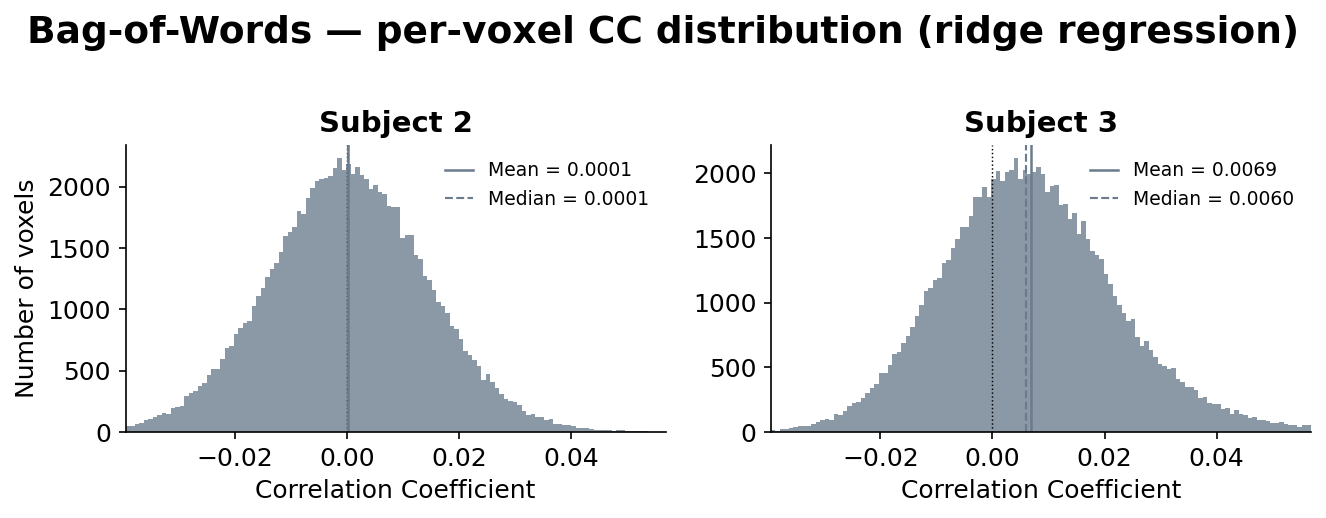

In [11]:
# color palette 
COL_BOW   = '#6B7B8D'   # slate grey — signals "baseline / not great"
COL_W2V   = '#2E7BB8'   # steel blue
COL_GLOVE = '#D4753A'   # terracotta orange

SUBJ_LABEL = {2: 'Subject 2', 3: 'Subject 3'}

#  BoW figure
bow_xlim = shared_xlim([cc_bow_s2, cc_bow_s3])

fig, axes = plt.subplots(1, 2, figsize=(9, 3.4), sharey=False)
fig.subplots_adjust(wspace=0.35)

for ax, arr, subj in zip(axes, [cc_bow_s2, cc_bow_s3], [2, 3]):
    hist_panel(ax, arr, color=COL_BOW, xlim=bow_xlim)
    ax.set_title(SUBJ_LABEL[subj], fontweight='bold')
    ax.set_xlabel('Correlation Coefficient')

axes[0].set_ylabel('Number of voxels')

fig.suptitle(
    'Bag-of-Words — per-voxel CC distribution (ridge regression)',
    fontsize=18, y=1.01, fontweight='bold'
)

plt.tight_layout()
# Save
#fig.savefig('figures/cc_bow_both_subjects.pdf', bbox_inches='tight')
fig.savefig('figures/cc_bow_both_subjects.png', dpi=300, bbox_inches='tight')
plt.show()
print('Saved figures/cc_bow_both_subjects.{pdf,png}')

## 4. Figure 2 — Word2Vec & GloVe


FileNotFoundError: [Errno 2] No such file or directory: 'figures/cc_static_both_subjects.pdf'

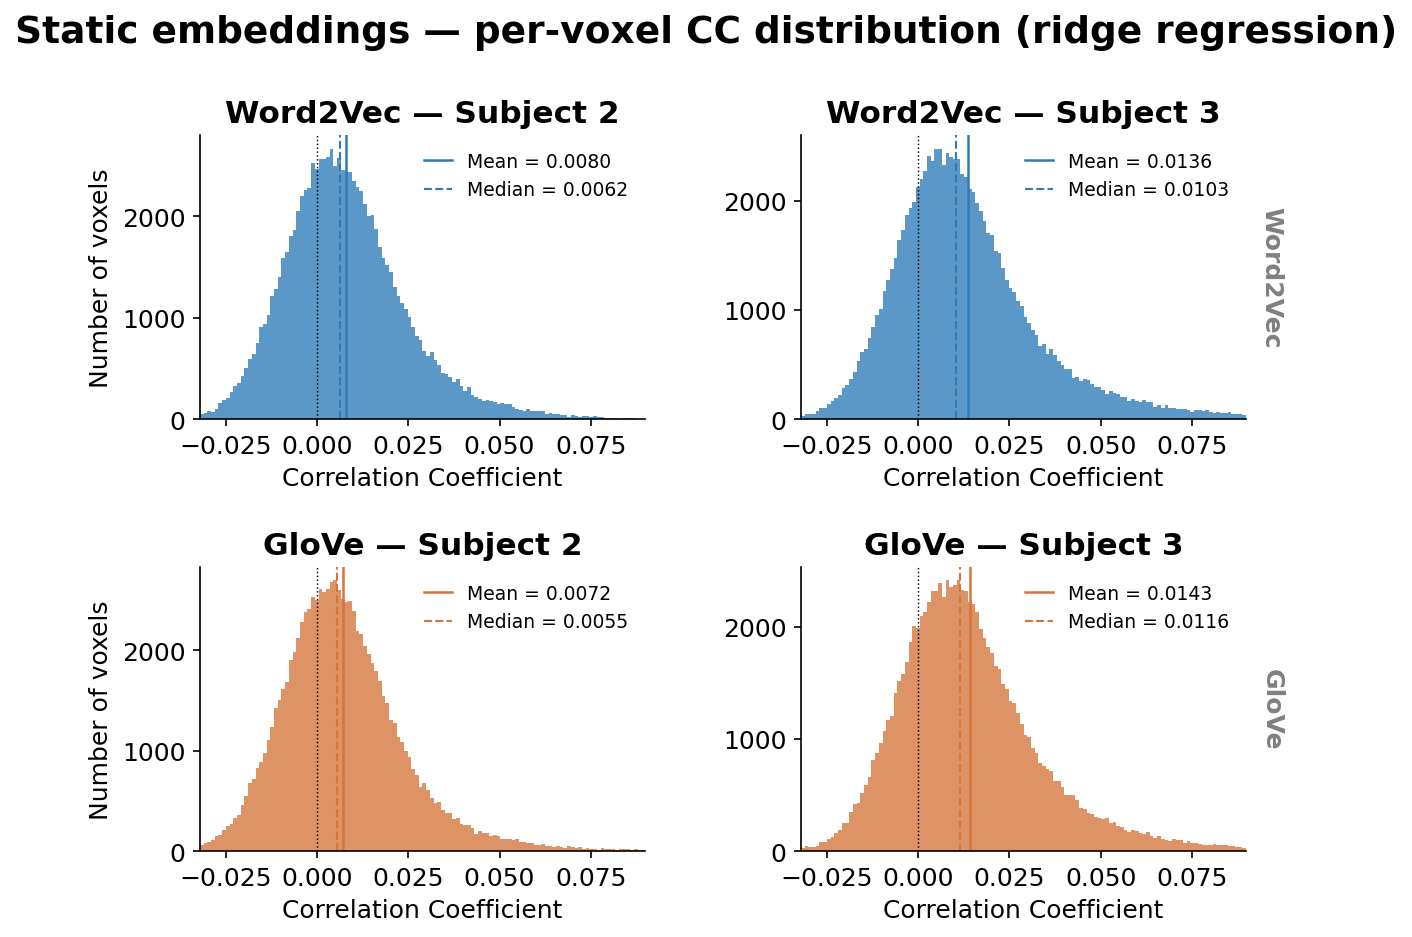

In [16]:
# ── Shared x-range across W2V + GloVe ─────────────────────────────────────────
static_xlim = shared_xlim([cc_w2v_s2, cc_w2v_s3, cc_glove_s2, cc_glove_s3])

fig = plt.figure(figsize=(9, 6.2))
gs  = gridspec.GridSpec(
    2, 2,
    hspace=0.52,   # vertical gap between rows
    wspace=0.35,   # horizontal gap between columns
)

ax_w2v_s2   = fig.add_subplot(gs[0, 0])
ax_w2v_s3   = fig.add_subplot(gs[0, 1])
ax_glove_s2 = fig.add_subplot(gs[1, 0])
ax_glove_s3 = fig.add_subplot(gs[1, 1])

panels = [
    (ax_w2v_s2,   cc_w2v_s2,   COL_W2V,   'Word2Vec — Subject 2'),
    (ax_w2v_s3,   cc_w2v_s3,   COL_W2V,   'Word2Vec — Subject 3'),
    (ax_glove_s2, cc_glove_s2, COL_GLOVE, 'GloVe — Subject 2'),
    (ax_glove_s3, cc_glove_s3, COL_GLOVE, 'GloVe — Subject 3'),
]

for ax, arr, col, title in panels:
    hist_panel(ax, arr, color=col, xlim=static_xlim)
    ax.set_title(title, fontsize=15, fontweight='bold')
    ax.set_xlabel('Correlation Coefficient')

# Only left column gets y-label
ax_w2v_s2.set_ylabel('Number of voxels')
ax_glove_s2.set_ylabel('Number of voxels')

# Row labels on the right margin
for ax, row_label in [(ax_w2v_s3, 'Word2Vec'), (ax_glove_s3, 'GloVe')]:
    ax.annotate(
        row_label,
        xy=(1.03, 0.5), xycoords='axes fraction',
        fontsize=12, fontweight='bold', color='grey',
        ha='left', va='center', rotation=270,
    )

fig.suptitle(
    'Static embeddings — per-voxel CC distribution (ridge regression)',
    fontsize=18, y=1.01, fontweight='bold'
)

fig.savefig('figures/cc_static_both_subjects.pdf', bbox_inches='tight')
fig.savefig('figures/cc_static_both_subjects.png', dpi=300, bbox_inches='tight')
plt.show()
print('Saved fig/cc_static_both_subjects.{pdf,png}')

FileNotFoundError: [Errno 2] No such file or directory: 'figures/cc_static_both_subjects.pdf'

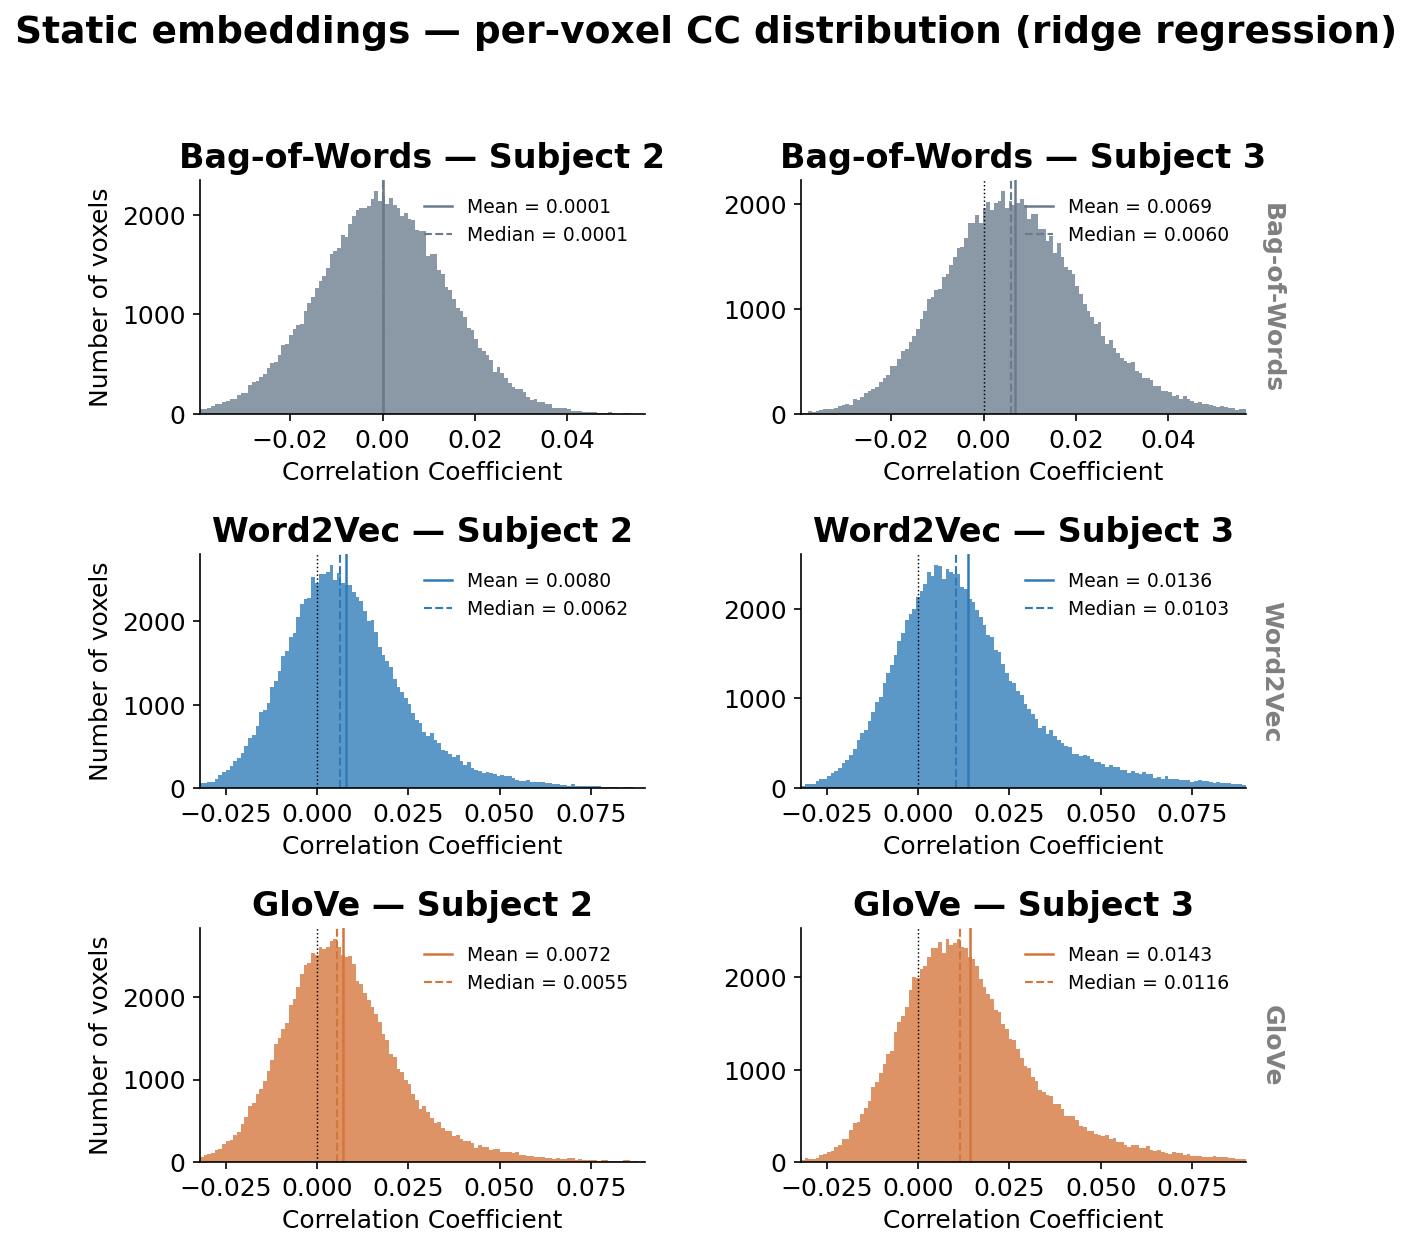

In [18]:
#  X-ranges: BoW gets its own; W2V + GloVe share one 
bow_xlim   = shared_xlim([cc_bow_s2, cc_bow_s3])
dense_xlim = shared_xlim([cc_w2v_s2, cc_w2v_s3, cc_glove_s2, cc_glove_s3])

fig = plt.figure(figsize=(9, 8.5))          
gs  = gridspec.GridSpec(
    3, 2,                                  
    hspace=0.6,
    wspace=0.35,
)

ax_bow_s2   = fig.add_subplot(gs[0, 0])
ax_bow_s3   = fig.add_subplot(gs[0, 1])
ax_w2v_s2   = fig.add_subplot(gs[1, 0])
ax_w2v_s3   = fig.add_subplot(gs[1, 1])
ax_glove_s2 = fig.add_subplot(gs[2, 0])
ax_glove_s3 = fig.add_subplot(gs[2, 1])

panels = [
    (ax_bow_s2,   cc_bow_s2,   COL_BOW,   bow_xlim,   'Bag-of-Words — Subject 2'),
    (ax_bow_s3,   cc_bow_s3,   COL_BOW,   bow_xlim,   'Bag-of-Words — Subject 3'),
    (ax_w2v_s2,   cc_w2v_s2,   COL_W2V,   dense_xlim, 'Word2Vec — Subject 2'),
    (ax_w2v_s3,   cc_w2v_s3,   COL_W2V,   dense_xlim, 'Word2Vec — Subject 3'),
    (ax_glove_s2, cc_glove_s2, COL_GLOVE, dense_xlim, 'GloVe — Subject 2'),
    (ax_glove_s3, cc_glove_s3, COL_GLOVE, dense_xlim, 'GloVe — Subject 3'),
]

for ax, arr, col, xlim, title in panels:  # xlim is now per-panel
    hist_panel(ax, arr, color=col, xlim=xlim)
    ax.set_title(title, fontsize=16, fontweight='bold')
    ax.set_xlabel('Correlation Coefficient')

# Left column y-labels 
for ax in [ax_bow_s2, ax_w2v_s2, ax_glove_s2]:
    ax.set_ylabel('Number of voxels')

# Row labels on the right margin 
for ax, row_label in [
    (ax_bow_s3,   'Bag-of-Words'),
    (ax_w2v_s3,   'Word2Vec'),
    (ax_glove_s3, 'GloVe'),
]:
    ax.annotate(
        row_label,
        xy=(1.03, 0.5), xycoords='axes fraction',
        fontsize=12, fontweight='bold', color='grey',
        ha='left', va='center', rotation=270,
    )

fig.suptitle(
    'Static embeddings — per-voxel CC distribution (ridge regression)',
    fontsize=18, y=1.01, fontweight='bold'
)

fig.savefig('figures/cc_static_both_subjects.pdf', bbox_inches='tight')
fig.savefig('figures/cc_static_both_subjects.png', dpi=300, bbox_inches='tight')
plt.show()
print('Saved figures/cc_static_both_subjects.{pdf,png}')

## 5. Optional: Overlay comparison (W2V vs GloVe per subject)

Useful for quickly checking whether W2V and GloVe distributions are nearly identical,
supporting the narrative in the report.

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4), sharey=False)
fig.subplots_adjust(wspace=0.35)

for ax, (arr_w2v, arr_glove), subj in zip(
    axes,
    [(cc_w2v_s2, cc_glove_s2), (cc_w2v_s3, cc_glove_s3)],
    [2, 3]
):
    xlim = shared_xlim([arr_w2v, arr_glove])

    ax.hist(finite(arr_w2v),   bins=120, range=xlim,
            color=COL_W2V,   alpha=0.55, linewidth=0, label='Word2Vec',
            density=True)   # density=True so histograms are comparable despite voxel-count differences
    ax.hist(finite(arr_glove), bins=120, range=xlim,
            color=COL_GLOVE, alpha=0.55, linewidth=0, label='GloVe',
            density=True)

    ax.axvline(finite(arr_w2v).mean(),   color=COL_W2V,   lw=1.2, ls='-')
    ax.axvline(finite(arr_glove).mean(), color=COL_GLOVE,  lw=1.2, ls='-')
    ax.axvline(0, color='black', lw=0.7, ls=':')
    ax.set_xlim(xlim)

    ax.set_title(SUBJ_LABEL[subj], fontweight='bold')
    ax.set_xlabel('Pearson $r$')
    ax.legend(fontsize=9)

axes[0].set_ylabel('Density')
fig.suptitle('Word2Vec vs GloVe overlay (density-normalised)', fontsize=13, y=1.01, fontweight='bold')
plt.tight_layout()
fig.savefig('fig/cc_w2v_vs_glove_overlay.pdf', bbox_inches='tight')
fig.savefig('fig/cc_w2v_vs_glove_overlay.png', dpi=300, bbox_inches='tight')
plt.show()

## 6. Summary stats table (for the LaTeX table)

Prints everything you need for `\\tab:static_results`.

In [ ]:
import pandas as pd

rows = []
for label, arr in [
    ('BoW',    2, cc_bow_s2),
    ('BoW',    3, cc_bow_s3),
    ('Word2Vec', 2, cc_w2v_s2),
    ('Word2Vec', 3, cc_w2v_s3),
    ('GloVe',  2, cc_glove_s2),
    ('GloVe',  3, cc_glove_s3),
]:
    f = finite(arr)
    rows.append({
        'Embedding': label[0],
        'Subject':   label[1],
        'Mean r':    round(f.mean(), 5),
        'Median r':  round(np.median(f), 5),
        'Top 1% r':  round(np.percentile(f, 99), 5),
        'Top 5% r':  round(np.percentile(f, 95), 5),
    })

# Unpack: label is actually (name, subject, arr)
# Re-do more cleanly:
rows = []
datasets = [
    ('BoW',      2, cc_bow_s2),
    ('BoW',      3, cc_bow_s3),
    ('Word2Vec', 2, cc_w2v_s2),
    ('Word2Vec', 3, cc_w2v_s3),
    ('GloVe',    2, cc_glove_s2),
    ('GloVe',    3, cc_glove_s3),
]
for name, subj, arr in datasets:
    f = finite(arr)
    rows.append({
        'Embedding': name,
        'Subject':   subj,
        'Mean r':    round(f.mean(), 5),
        'Median r':  round(np.median(f), 5),
        'Top 1% r':  round(np.percentile(f, 99), 5),
        'Top 5% r':  round(np.percentile(f, 95), 5),
    })

df = pd.DataFrame(rows)
display(df)
print('\n--- LaTeX snippet ---')
print(df.to_latex(index=False, float_format='%.5f'))